# Parking anywhere

Step 12.2. Two boxes put down by hand anywhere in the room: at rest the car finds them among the lidar points its map
does not have, plans a path to where the parking starts, drives it with the NMPC (Phase 9), backs up along the boxes
when that start cannot be reached driving forward, and parks sideways between them (`sideways.ipynb`).
`valet.launch.py`: `valet_node` plans (`ackermann_nmpc/valet.py`) and exits, `nmpc_node` drives the path, `gap_node`
backs up and parks; each starts when the one before ended well (exit code 0). The runs: `valet_1`-`4` in the room
(`maps/room`), `valet_r2_*` under the video's camera (`maps/room2`) at three places of the boxes, each from the start
mark of its map.

In [1]:
import sys
sys.path.append('../scripts')
sys.path.append('../ros2_ws/src/ackermann_nmpc')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from PIL import Image
from scipy import ndimage
import lidar_path
from ackermann_nmpc import valet

plt.rcParams['figure.dpi'] = 72
B = '../data/bags'
MAPS = '../ros2_ws/src/ackermann_bringup/maps'
lidar_path.B = B
FRONT, REAR, HALF = 0.2165, -0.0435, 0.10     # car outline from the rear axle
OUTLINE = np.array([[x, y] for x in np.linspace(REAR, FRONT, 30) for y in (-HALF, HALF)] +
                   [[x, y] for x in (REAR, FRONT) for y in np.linspace(-HALF, HALF, 10)])
LAG = 0.055                                    # the lidar path's time against the car's (identification.ipynb)
MARKS = {'room': (3.010, 0.350, np.radians(-45.9)), 'room2': (2.9437, -0.7015, 0.7429)}
# map, kick_ahead, kick_left, sweep, reverse allowed: as each ran (valet.launch.py; the reverse came after valet_2)
RUNS = {'valet_1': ('room', 0.30, 0.42, 0.15, False), 'valet_2': ('room', 0.30, 0.42, 0.15, False),
        'valet_3': ('room', 0.30, 0.42, 0.15, True), 'valet_4': ('room', 0.30, 0.42, 0.0, True),
        'valet_r2_1': ('room2', 0.30, 0.42, 0.15, True), 'valet_r2_1b': ('room2', 0.30, 0.42, 0.15, True),
        'valet_r2_1c': ('room2', 0.30, 0.42, 0.15, True), 'valet_r2_2': ('room2', 0.30, 0.42, 0.15, True),
        'valet_r2_2b': ('room2', 0.20, 0.42, 0.15, True), 'valet_r2_2c': ('room2', 0.20, 0.42, 0.15, True),
        'valet_r2_3': ('room2', 0.30, 0.42, 0.15, True)}


def read(run, name):
    return pd.read_parquet(f'{B}/{run}_parquet/{name}.parquet')


class Map:
    def __init__(self, name):
        m = yaml.safe_load(open(f'{MAPS}/{name}.yaml'))
        self.img = np.array(Image.open(f'{MAPS}/{m["image"]}'))
        self.res, (self.ox, self.oy) = m['resolution'], m['origin'][:2]
        self.dist = ndimage.distance_transform_edt(self.img != 0) * self.res     # m to the nearest wall cell
        rows, cols = np.nonzero(self.img == 0)
        self.walls = np.c_[self.ox + (cols + 0.5) * self.res, self.oy + (self.img.shape[0] - rows - 0.5) * self.res]
        self.mark = MARKS[name]

    def wall_dist(self, p):
        r = np.clip(self.img.shape[0] - 1 - np.floor((p[:, 1] - self.oy) / self.res).astype(int), 0, self.img.shape[0] - 1)
        c = np.clip(np.floor((p[:, 0] - self.ox) / self.res).astype(int), 0, self.img.shape[1] - 1)
        return self.dist[r, c]

    def extent(self):
        return (self.ox, self.ox + self.img.shape[1] * self.res, self.oy, self.oy + self.img.shape[0] * self.res)


MAP = {name: Map(name) for name in ('room', 'room2')}


def compose(p, d):
    x, y, h = p
    return x + np.cos(h) * d[0] - np.sin(h) * d[1], y + np.sin(h) * d[0] + np.cos(h) * d[1], h + d[2]


def body(x, y, h):
    return np.c_[x + np.cos(h) * OUTLINE[:, 0] - np.sin(h) * OUTLINE[:, 1], y + np.sin(h) * OUTLINE[:, 0] + np.cos(h) * OUTLINE[:, 1]]


def stretch(run, t0, t1):
    # the lidar path from rest at t0: rear axle x, y and heading on a 10 ms grid, in the frame of the car at t0
    L, G = lidar_path.path(run, t0, t1)
    t = np.arange(L['t'].iloc[0], L['t'].iloc[-1], 0.01) - LAG
    psi = np.interp(t, G['t'] - LAG, G['psi']) + np.interp(t, L['t'] - LAG, L['dyaw'])
    return pd.DataFrame({'t': t, 'x': np.interp(t, L['t'] - LAG, L['x']), 'y': np.interp(t, L['t'] - LAG, L['y']), 'psi': psi})


def scan_points(m, lidar_x=lidar_path.LIDAR_X):
    r = np.array(m['ranges'], float); a = m['angle_min'] + np.arange(len(r)) * m['angle_increment']
    ok = np.isfinite(r) & (r > 0.15) & (r < 5.0)
    return np.c_[r[ok] * np.cos(a[ok]) + lidar_x, r[ok] * np.sin(a[ok])]


def localization(run, t):
    # the map pose at t as the nodes take it: the newest AMCL correction on the newest odometry
    a, o = read(run, 'amcl_pose'), read(run, 'odometry_filtered')
    e = a[a['t'] < t].iloc[-1]
    k = np.argmin(np.abs(o['stamp'] - e['stamp']))
    c = compose((e['x'], e['y'], e['yaw']), compose((0, 0, -o['yaw'].iloc[k]), (-o['x'].iloc[k], -o['y'].iloc[k], 0)))
    q = o[o['t'] < t].iloc[-1]
    return np.array(compose(c, (q['x'], q['y'], q['yaw'])))


def on_mark(run, mp):
    # the car at rest near the mark: the pose that lays the most of its first five scans within 5 cm of a wall
    p = np.vstack([scan_points(m) for _, m in read(run, 'scan').iloc[:5].iterrows()])

    def share(x, y, h):
        w = np.c_[x + np.cos(h) * p[:, 0] - np.sin(h) * p[:, 1], y + np.sin(h) * p[:, 0] + np.cos(h) * p[:, 1]]
        return (mp.wall_dist(w) < 0.05).mean()

    mk = mp.mark
    best = max((share(mk[0] + dx, mk[1] + dy, mk[2] + dh), dx, dy, dh) for dx in np.arange(-0.2, 0.21, 0.02)
               for dy in np.arange(-0.2, 0.21, 0.02) for dh in np.radians(np.arange(-6, 6.1, 1.0)))
    for step, hs in ((0.005, np.radians(0.2)), (0.002, np.radians(0.05))):
        _, dx, dy, dh = best
        best = max((share(mk[0] + dx + a * step, mk[1] + dy + b * step, mk[2] + dh + e * hs), dx + a * step, dy + b * step, dh + e * hs)
                   for a in range(-4, 5) for b in range(-4, 5) for e in range(-4, 5))
    return np.array([mk[0] + best[1], mk[1] + best[2], mk[2] + best[3]])


def find_gap(p):
    # as gap_node: the side of the boxes the nearest line of points at the angle where most points line up on it,
    # refined by a straight line through them; the rows along it, the widest stretch between them
    best, face, near = 0, 0.0, 0.0
    for a in np.arange(-np.radians(20), np.radians(20) + 1e-9, np.radians(0.5)):
        ys = -np.sin(a) * p[:, 0] + np.cos(a) * p[:, 1]
        n = np.sort(ys)[len(ys) // 10]
        on = np.sum(np.abs(ys - n) < 0.015)
        if on > best:
            best, face, near = on, a, n
    q = p[np.abs(-np.sin(face) * p[:, 0] + np.cos(face) * p[:, 1] - near) < 0.015]
    face = np.arctan(np.polyfit(q[:, 0], q[:, 1], 1)[0])
    fx, fy = np.cos(face) * p[:, 0] + np.sin(face) * p[:, 1], -np.sin(face) * p[:, 0] + np.cos(face) * p[:, 1]
    n = np.sort(fy)[len(fy) // 10]
    band = np.abs(fy - n) < 0.03
    sx = np.sort(fx[band])
    i = np.argmax(np.where(np.diff(sx) > 0.10, np.diff(sx), 0))
    return np.degrees(face), np.median(fy[band]), sx[i], sx[i + 1]

/home/pietro/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## The gap

The five scans at rest laid on the map by the localization; the points more than 10 cm from the map's walls are new.
Groups of them 15-105 cm across are boxes; of two boxes 0.4-1.45 m apart, the line on which most of their points
facing the car lie (within 1.5 cm); the gap the stretch of that line between them, 0.40-0.75 m. Each run as
`valet_node` saw it, the gap against the one `gap_node` measured from the car at rest before its run-up, and the three
places under the camera:

In [2]:
def planned(run):
    # what valet_node had: the localization and the five scans at rest before the NMPC started, the gap, the plan
    name, ka, kl, sweep, rev = RUNS[run]
    mp = MAP[name]
    t = read(run, 'nmpc_solve_time')['t'].iloc[0] - 1.0
    pose = localization(run, t)
    pts = []
    for _, m in read(run, 'scan').loc[lambda s: s['t'] < t].iloc[-5:].iterrows():
        p = scan_points(m)
        pts.append(np.c_[pose[0] + np.cos(pose[2]) * p[:, 0] - np.sin(pose[2]) * p[:, 1], pose[1] + np.sin(pose[2]) * p[:, 0] + np.cos(pose[2]) * p[:, 1]])
    new = valet.new_points(np.vstack(pts), mp.wall_dist)
    gap = valet.find_gap(new, pose)
    goal = valet.parking_start(*gap, ka, kl, sweep, 0.02, 0.6)
    path, back = valet.plan(pose, goal, np.vstack([mp.walls, new]), reverse_max=3.0 if rev else 0.0)
    return {'map': name, 'pose': pose, 'new': new, 'gap': gap, 'goal': goal, 'path': path, 'back': back}


P = {run: planned(run) for run in RUNS}
rows = []
for run, p in P.items():
    st = read(run, 'gap_state')
    t_rest = st.loc[st['phase'] == 2, 't'].iloc[0]
    sc = read(run, 'scan')
    near = np.vstack([q for q in (scan_points(m) for _, m in sc[sc['t'] < t_rest].iloc[-5:].iterrows())])
    near = near[(near[:, 0] > -0.3) & (near[:, 0] < 2.5) & (near[:, 1] > 0.1) & (near[:, 1] < 1.2)]
    face, side, g0, g1 = find_gap(near)
    c, d, a, b = p['gap']
    rows.append({'run': run, 'map': p['map'], 'new points': len(p['new']), 'gap seen from the start [m]': b - a,
                 'gap at the run-up [m]': g1 - g0, 'approach [m]': p['path'][-1, 0], 'backing up [m]': p['back']})
gaps = pd.DataFrame(rows).set_index('run')
gaps.round(3)

,map,new points,gap seen from the start [m],gap at the run-up [m],approach [m],backing up [m]
run,,,,,,
valet_1,room,742,0.578,0.545,1.635,0.0
valet_2,room,812,0.646,0.642,4.516,0.0
valet_3,room,957,0.635,0.647,1.635,2.5
valet_4,room,1081,0.637,0.645,1.651,2.5
valet_r2_1,room2,1215,0.541,0.559,2.723,0.0
valet_r2_1b,room2,1433,0.543,0.561,2.714,0.0
valet_r2_1c,room2,1384,0.537,0.562,2.713,0.0
valet_r2_2,room2,1472,0.627,0.637,1.239,0.9
valet_r2_2b,room2,1522,0.636,0.627,1.138,0.7


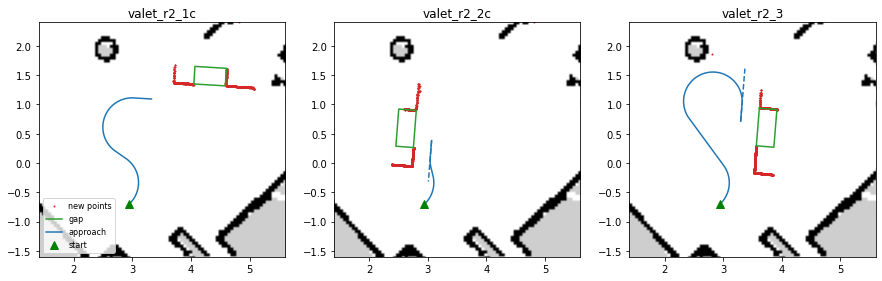

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, run in zip(axs, ['valet_r2_1c', 'valet_r2_2c', 'valet_r2_3']):
    p = P[run]
    mp = MAP[p['map']]
    ax.imshow(mp.img, cmap='gray', extent=mp.extent())
    ax.plot(p['new'][:, 0], p['new'][:, 1], '.', color='tab:red', ms=2, label='new points')
    c, d, a, b = p['gap']
    left = np.array([-d[1], d[0]])
    q = np.array([c + a * d, c + b * d, c + b * d + 0.3 * left, c + a * d + 0.3 * left, c + a * d])
    ax.plot(q[:, 0], q[:, 1], color='tab:green', label='gap')
    ax.plot(p['path'][:, 1], p['path'][:, 2], color='tab:blue', label='approach')
    if p['back'] > 0:
        e = p['goal'][:2] + p['back'] * np.array([np.cos(p['goal'][2]), np.sin(p['goal'][2])])
        ax.plot([e[0], p['goal'][0]], [e[1], p['goal'][1]], '--', color='tab:blue', label='backing up')
    ax.plot(*p['pose'][:2], 'g^', ms=8, label='start')
    ax.set_xlim(1.4, 5.6); ax.set_ylim(-1.6, 2.4); ax.set_aspect('equal'); ax.set_title(run)
axs[0].legend(loc='lower left', fontsize=8)
plt.show()

## The approach

From where the parking starts (`valet.parking_start`: on the faces' line as `gap_node` starts from rest, 0.6 m of
run-up before its kick) back along that line, the shortest of the arc-straight-arc paths of radius 0.5 m that end on
0.3 m of the line with the car's outline 5 cm clear of the walls and of the new points at every pose. When there is
none, or when a path to a point further along the line and backing up from there costs less (a metre backed up counts
as two driven), that one: `gap_node` backs up at 0.3 m/s holding the heading of the faces, then measures the boxes and
parks. Speed as on the gymkhana's paths, 0.8 m/s at most.

## On the car

The truth the lidar path from the start (the car's place on its start mark fitted on the map's walls), the approach
against the plan while the NMPC drove it, the localization against the truth at the start, and the parking in the
frame of the boxes as the gap node measured them at rest (`gymkhana.ipynb`):

In [4]:
def segments(run):
    # the stretches the wheels turn, from rest: (start, the start of the next or the end of the bag)
    j = read(run, 'joint_states')
    moving = ((j['wl'] + j['wr']).abs() > 0.05).to_numpy()
    t = j['t'].to_numpy()
    starts = t[1:][moving[1:] & ~moving[:-1]]
    stops = t[1:][~moving[1:] & moving[:-1]]
    seg = []
    for a in starts:
        b = stops[stops > a]
        if len(b) and b[0] - a > 0.5 and (not seg or a - seg[-1][1] > 1.0):
            seg.append([a, b[0]])
        elif seg and len(b):
            seg[-1][1] = b[0]
    return [(a, (seg[i + 1][0] if i + 1 < len(seg) else t[-1]) - 0.2) for i, (a, _) in enumerate(seg)]


def dist_box(q, b):
    dx = np.maximum(np.maximum(b[0] - q[:, 0], q[:, 0] - b[1]), 0); dy = np.maximum(np.maximum(b[2] - q[:, 1], q[:, 1] - b[3]), 0)
    inside = (q[:, 0] > b[0]) & (q[:, 0] < b[1]) & (q[:, 1] > b[2]) & (q[:, 1] < b[3])
    return np.where(inside, -1.0, np.hypot(dx, dy)).min()


def on_car(run):
    p = P[run]
    mp = MAP[p['map']]
    start = on_mark(run, mp)
    seg = segments(run)
    # one lidar path from rest on the mark to the end: after backing up the car rests ~1.3 s, too short for a path's
    # reference scans (1.5 s)
    s = stretch(run, seg[0][0], seg[-1][1])
    x, y, h = compose(start, (s['x'].to_numpy(), s['y'].to_numpy(), s['psi'].to_numpy()))
    drive = (s['t'] < read(run, 'nmpc_solve_time')['t'].iloc[-1]).to_numpy()
    path = p['path']
    k = np.argmin(np.hypot(path[:, 1] - x[drive, None], path[:, 2] - y[drive, None]), axis=1)
    e = -(x[drive] - path[k, 1]) * np.sin(path[k, 3]) + (y[drive] - path[k, 2]) * np.cos(path[k, 3])
    on_path = path[k, 0] < path[-1, 0] - 0.05
    # the parking from rest before its run-up, in the frame of the boxes measured there
    st = read(run, 'gap_state')
    tp = st.loc[st['phase'] == 2, 't'].iloc[0]
    j = read(run, 'joint_states')
    tq = j.loc[((j['wl'] + j['wr']).abs() > 0.05) & (j['t'] > tp - 0.3), 't'].iloc[0]     # the run-up starts, from rest
    sc = read(run, 'scan')
    near = np.vstack([scan_points(m) for _, m in sc[sc['t'] < tq].iloc[-5:].iterrows()])
    near = near[(near[:, 0] > -0.3) & (near[:, 0] < 2.5) & (near[:, 1] > 0.1) & (near[:, 1] < 1.2)]
    face, side, g0, g1 = find_gap(near)
    f = np.radians(face)
    # the parking relative to the car at rest before its run-up, then in the frame of the boxes measured there
    k0 = np.searchsorted(s['t'].to_numpy(), tq)
    q = s.iloc[k0:]
    p0 = s['psi'].iloc[k0]
    dx, dy = q['x'] - s['x'].iloc[k0], q['y'] - s['y'].iloc[k0]
    rx, ry = np.cos(p0) * dx + np.sin(p0) * dy, -np.sin(p0) * dx + np.cos(p0) * dy
    xb, yb, hb = np.cos(f) * rx + np.sin(f) * ry, -np.sin(f) * rx + np.cos(f) * ry, q['psi'] - p0 - f
    A, Bx = (g0 - 0.33, g0, side, side + 0.36), (g1, g1 + 0.475, side, side + 0.30)
    sweep = RUNS[run][3]
    mid = (FRONT + REAR) / 2
    return {'run': run, 'off the mark [cm]': 100 * np.hypot(*(start[:2] - mp.mark[:2])),
            'localization off at the start [cm]': 100 * np.hypot(*(p['pose'][:2] - start[:2])),
            'from the plan rms [cm]': 100 * np.sqrt(np.mean(e[on_path] ** 2)), 'max [cm]': 100 * np.abs(e[on_path]).max(),
            'gap [m]': g1 - g0, 'stop [deg]': np.degrees(hb.iloc[-1]),
            'middle against its aim [cm]': 100 * (xb.iloc[-1] + np.cos(hb.iloc[-1]) * mid - g0 - (g1 - g0 - sweep) / 2),
            'box A [cm]': 100 * min(dist_box(body(a, b, c), A) for a, b, c in zip(xb, yb, hb)),
            'box B [cm]': 100 * min(dist_box(body(a, b, c), Bx) for a, b, c in zip(xb, yb, hb))}


runs = pd.DataFrame([on_car(run) for run in RUNS]).set_index('run')
pd.set_option('display.width', 200)
runs.round(1)

,off the mark [cm],localization off at the start [cm],from the plan rms [cm],max [cm],gap [m],stop [deg],middle against its aim [cm],box A [cm],box B [cm]
run,,,,,,,,,
valet_1,0.3,0.1,1.4,3.1,0.5,188.4,-7.4,-100.0,6.9
valet_2,0.0,0.6,3.4,6.5,0.6,178.6,-4.3,6.9,15.8
valet_3,0.5,0.6,4.3,8.1,0.6,182.1,-1.5,9.9,13.3
valet_4,0.5,0.2,2.0,3.9,0.6,179.9,-2.7,15.1,8.8
valet_r2_1,1.6,2.1,4.8,9.1,0.6,175.2,2.4,8.8,7.5
valet_r2_1b,2.0,1.7,4.0,9.2,0.6,188.2,3.0,9.2,7.1
valet_r2_1c,1.7,1.6,3.4,8.1,0.6,185.0,0.8,7.5,8.5
valet_r2_2,4.2,3.8,3.3,5.5,0.6,186.8,1.1,11.0,11.5
valet_r2_2b,4.2,4.0,2.9,4.1,0.6,191.4,8.7,17.8,2.2


A box at -100 is a body inside its outline.

### Result

Eleven runs at six places of the boxes, each planned from the start mark: gaps of 0.54-0.65 m, approaches of
1.1-4.5 m, six of them backing up 0.7-2.5 m. The NMPC drove the planned path 1.4-4.8 cm rms from it by the lidar (9.2 at
most), the localization 0.1-4.9 cm off at the start. Stops 175.2-191.4 deg, the spread of the slide after the brake on
each patch of floor (`sideways.ipynb`). The body touched a box once, the nose box A in `valet_1`; otherwise at least
6.9 cm from box A and 0.8 cm from box B. At the second place the kick went 10 cm later after the first run (`kick_ahead`
0.20): the stops went 8-11 cm further, to within 0.8-2.2 cm of box B. That first run had looked 11 cm short by an
evaluation whose lidar path started in the 1.3 s of rest after backing up; the path from the start mark, as here,
puts it 1.1 cm from its aim.